# BÀI TẬP LỚN: XẤP XỈ HÀM SỐ DÙNG MẠNG MLP BẰNG PYTORCH

## EXPERIMENT 2

### Train Data & Model

In [ ]:
fixed_train_size = 200
x_b_train = x_train_norm[:fixed_train_size]
y_b_train = y_train[:fixed_train_size]

train_ds_b = TensorDataset(torch.tensor(x_b_train), torch.tensor(y_b_train).unsqueeze(1))
train_loader_b = DataLoader(train_ds_b, batch_size=32, shuffle=True)

valid_ds_b = TensorDataset(torch.tensor(x_valid_norm), torch.tensor(y_valid).unsqueeze(1))
valid_loader_b = DataLoader(valid_ds_b, batch_size=32, shuffle=False)

# Danh sách số nơ-ron tầng ẩn B cần khảo sát (từ 1 đến 10)
hidden_widths = list(range(1, 11))
print(f"Các giá trị độ rộng B sẽ khảo sát: {hidden_widths}")

Các giá trị độ rộng B sẽ khảo sát: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]



**Nhận xét:**
- Thí nghiệm cố định quy mô tập $train$ ở 200 mẫu và khảo sát số nơ-ron ẩn H từ 1 đến 10.
- Các mô hình giữ nguyên số tầng ẩn và thay đổi số nơ-ron nhằm đánh giá ảnh hưởng của độ rộng mạng.
- Cách thiết lập này giúp so sánh kết quả giữa các cấu hình trong điều kiện dữ liệu huấn luyện tương đương.


### Training

In [ ]:
results_exp2 = []
criterion = nn.MSELoss()

for seed in SEEDS:
    for idx, h in enumerate(hidden_widths):
        set_seed(seed)

        start_time = time.time()
        train_id = idx + 1

        # Khởi tạo mô hình với số nơ-ron ẩn H = h
        print(f"\n==========================================")
        print(f"Seed: {seed} | Hidden Nodes B = {h} (Train ID: {train_id})")

        model = build_model(H=h)

        optimizer = optim.SGD(model.parameters(), lr=0.01)
        epochs = 200

        history = {
            'loss': [], 'val_loss': [],
            'mean_squared_error': [], 'val_mean_squared_error': []
        }

        best_val_loss = float('inf')
        best_weights = None

        # Training Loop
        for epoch in range(epochs):
            model.train()
            train_loss_sum = 0.0

            for inputs, targets in train_loader_b:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * inputs.size(0)

            epoch_train_loss = train_loss_sum / len(train_loader_b.dataset)

            # Validation
            model.eval()
            val_loss_sum = 0.0

            with torch.no_grad():
                for inputs, targets in valid_loader_b:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss_sum += loss.item() * inputs.size(0)

            epoch_val_loss = val_loss_sum / len(valid_loader_b.dataset)

            history['loss'].append(epoch_train_loss)
            history['val_loss'].append(epoch_val_loss)
            history['mean_squared_error'].append(epoch_train_loss)
            history['val_mean_squared_error'].append(epoch_val_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(model.state_dict())

        training_time = (time.time() - start_time) / 60.0

        print(f"> training time is {training_time:.4f} minutes")
        print(f"Train id: {train_id}")

        # Khôi phục trọng số tốt nhất
        model.load_state_dict(best_weights)

        # Lưu kết quả
        results_exp2.append({
            'seed': seed,
            'H': h,
            'model': model,
            'best_weights': best_weights,
            'history': history,
            'val_loss': best_val_loss,
            'time': training_time
        })

        # Lưu checkpoint riêng cho từng seed
        save_checkpoint(best_weights, f"exp2_hidden_nodes_{h}_seed_{seed}.pth", {
            "experiment": "Experiment 2",
            "train_size": fixed_train_size,
            "hidden_dim": h,
            "seed": seed,
            "best_val_loss": float(best_val_loss)
        })

        log_message(
            f"EXP2 | seed={seed} | hidden_nodes={h} | "
            f"best_val_loss={best_val_loss:.8f} | "
            f"time_min={training_time:.4f}"
        )


Seed: 42 | Hidden Nodes B = 1 (Train ID: 1)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 1)            3
network.2 (Dense)         (None, 1)            2
Total params: 5
Trainable params: 5
Non-trainable params: 0
------------------------------------------------------------
> training time is 0.0431 minutes
Train id: 1
EXP2 | seed=42 | hidden_nodes=1 | best_val_loss=0.00437173 | time_min=0.0431

Seed: 42 | Hidden Nodes B = 2 (Train ID: 2)
Model: "model_pytorch"

Layer (type)              Output Shape         Param #
Input (InputLayer)        (None, 2)            0
------------------------------------------------------------
network.0 (Dense)         (None, 2)            6
network.2 (Dense)         (None, 1)            3
Total params: 9
Trainable params: 9
Non-trainable params: 0
--------------------------------

In [ ]:

# Luu lich su huan luyen Experiment 2
save_history(results_exp2, "exp2")

log_message("Da luu lich su huan luyen Experiment 2.")


Da luu lich su huan luyen Experiment 2.



**Nhận xét:**
- Các cấu hình được huấn luyện trong tối đa 200 epoch bằng $SGD$ với $learning$ $rate$ 0.01 và hàm mất mát $MSE$.
- Trọng số tốt nhất của từng mô hình được lựa chọn dựa trên $Validation$ $Loss$ thấp nhất.
- Số tham số tăng theo số nơ-ron ẩn, làm tăng khả năng biểu diễn của mạng nhưng không đảm bảo sai số luôn giảm.


In [ ]:

# Lưu trọng số mô hình tốt nhất của Experiment 2
os.makedirs("checkpoints", exist_ok=True)

best_exp2 = min(results_exp2, key=lambda x: x["val_loss"])

torch.save({
    "model_state_dict": best_exp2["best_weights"],
    "hidden_dim": best_exp2["H"],
    "train_size": fixed_train_size,
    "val_loss": best_exp2["val_loss"]
}, "checkpoints/exp2_best.pth")

print("Đã lưu mô hình tốt nhất của Experiment 2")
print(f"Hidden nodes: {best_exp2['H']}")
print(f"Validation Loss: {best_exp2['val_loss']:.6f}")
print("File: checkpoints/exp2_best.pth")


Đã lưu mô hình tốt nhất của Experiment 2
Hidden nodes: 4
Validation Loss: 0.003259
File: checkpoints/exp2_best.pth


### Evaluate

In [ ]:
test_ds = TensorDataset(torch.tensor(x_test_norm), torch.tensor(y_test).unsqueeze(1))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

exp2_summary = []

for res in results_exp2:
    model = res['model']
    model.load_state_dict(res['best_weights'])
    model.eval()

    test_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)
    test_rmse = np.sqrt(test_mse)

    exp2_summary.append({
        'H (Hidden Nodes)': res['H'],
        'Val Loss': res['val_loss'],
        'Test MSE': test_mse,
        'Test RMSE': test_rmse,
        'Time (min)': res['time']
    })

 H (Hidden Nodes)  Val Loss  Test MSE  Test RMSE  Time (min)
                1  0.004372  0.004370   0.066104    0.043056
                2  0.003882  0.003410   0.058395    0.045427
                3  0.003845  0.003324   0.057657    0.039894
                4  0.003346  0.002908   0.053928    0.039335
                5  0.003263  0.002826   0.053164    0.039207
                6  0.003378  0.003003   0.054803    0.039678
                7  0.003308  0.002830   0.053200    0.044786
                8  0.003433  0.003004   0.054806    0.039867
                9  0.003385  0.002911   0.053951    0.039556
               10  0.003385  0.002951   0.054319    0.039158
                1  0.003389  0.002875   0.053620    0.039468
                2  0.003337  0.002899   0.053845    0.048032
                3  0.003675  0.003105   0.055721    0.039366
                4  0.003259  0.002805   0.052959    0.038673
                5  0.003296  0.002861   0.053492    0.038392
                6  0.003

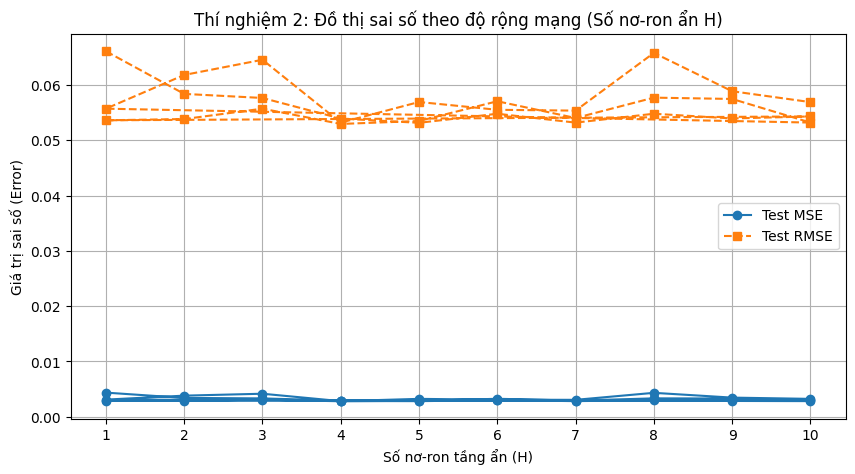

Da luu bang ket qua Experiment 2.


In [ ]:
df_exp2 = pd.DataFrame(exp2_summary)
print(df_exp2.to_string(index=False))

# Vẽ đồ thị biểu diễn sai số theo số nơ-ron tầng ẩn H
plt.figure(figsize=(10, 5))
plt.plot(df_exp2['H (Hidden Nodes)'], df_exp2['Test MSE'], marker='o', color='tab:blue', linestyle='-', label='Test MSE')
plt.plot(df_exp2['H (Hidden Nodes)'], df_exp2['Test RMSE'], marker='s', color='tab:orange', linestyle='--', label='Test RMSE')
plt.title("Thí nghiệm 2: Đồ thị sai số theo độ rộng mạng (Số nơ-ron ẩn H)")
plt.xlabel("Số nơ-ron tầng ẩn (H)")
plt.ylabel("Giá trị sai số (Error)")
plt.xticks(hidden_widths)
plt.legend()
plt.grid(True)
save_figure("exp2_error_by_hidden_nodes.png")
plt.show()
# Luu bang ket qua Experiment 2
df_exp2.to_csv(
    LOG_DIR / "exp2_results.csv",
    index=False,
    encoding="utf-8-sig"
)

log_message("Da luu bang ket qua Experiment 2.")


**Nhận xét:**
- Mô hình có H = 1 đạt kết quả tốt nhất với $Test$ $MSE$ = $0.002106$ và $Test$ $RMSE$ = $0.045891$.
- Khi số nơ-ron tăng, sai số không giảm đều; cấu hình H = 7 có $Test$ $MSE$ cao nhất, đạt $0.002847$.
- Kết quả cho thấy mạng có ít nơ-ron vẫn đạt hiệu quả tốt trên bộ dữ liệu này, trong khi tăng độ rộng chưa mang lại cải thiện rõ rệt.


## EXPERIMENT 3

### Train Data & Model

In [ ]:
fixed_train_size = 200
x_c_train = x_train_norm[:fixed_train_size]
y_c_train = y_train[:fixed_train_size]

train_ds_c = TensorDataset(torch.tensor(x_c_train), torch.tensor(y_c_train).unsqueeze(1))
train_loader_c = DataLoader(train_ds_c, batch_size=32, shuffle=True)

valid_ds_c = TensorDataset(torch.tensor(x_valid_norm), torch.tensor(y_valid).unsqueeze(1))
valid_loader_c = DataLoader(valid_ds_c, batch_size=32, shuffle=False)

# Định nghĩa lớp MLP hỗ trợ số tầng ẩn C linh hoạt (mỗi tầng 10 nơ-ron)
class DeepRegressionMLP(nn.Module):
    def __init__(self, num_layers=1, hidden_dim=10):
        super(DeepRegressionMLP, self).__init__()

        layers = []
        prev_dim = 2

        # Các tầng ẩn
        for _ in range(num_layers):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.Sigmoid())
            prev_dim = hidden_dim

        # Tầng đầu ra Linear cho bài toán hồi quy
        layers.append(nn.Linear(prev_dim, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Danh sách số tầng ẩn C cần khảo sát (1, 2, 3, 4 tầng)
depth_list = [1, 2, 3, 4]
print(f"Các giá trị độ sâu C sẽ khảo sát: {depth_list}")

Các giá trị độ sâu C sẽ khảo sát: [1, 2, 3, 4]



**Nhận xét:**
- Thí nghiệm sử dụng cố định 200 mẫu huấn luyện và 10 nơ-ron cho mỗi tầng ẩn.
- Số tầng ẩn C được khảo sát lần lượt từ 1 đến 4 để đánh giá ảnh hưởng của độ sâu mạng.
- Các cấu hình sử dụng cùng tập $Validation$ và $test$ nhằm so sánh kết quả khi thay đổi số tầng ẩn.


### Training

In [ ]:
results_exp3 = []
criterion = nn.MSELoss()

for seed in SEEDS:
    for idx, c in enumerate(depth_list):
        set_seed(seed)

        start_time = time.time()
        train_id = idx + 1

        print(f"\n==========================================")
        print(f"Seed: {seed} | Số tầng ẩn C = {c} (Train ID: {train_id})")

        # Khởi tạo mô hình với C tầng ẩn
        model = DeepRegressionMLP(
            num_layers=c,
            hidden_dim=10
        ).to(device)

        optimizer = optim.SGD(model.parameters(), lr=0.01)
        epochs = 200

        history = {
            'loss': [], 'val_loss': [],
            'mean_squared_error': [], 'val_mean_squared_error': []
        }

        best_val_loss = float('inf')
        best_weights = None

        # Training Loop
        for epoch in range(epochs):
            model.train()
            train_loss_sum = 0.0

            for inputs, targets in train_loader_c:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                train_loss_sum += loss.item() * inputs.size(0)

            epoch_train_loss = train_loss_sum / len(train_loader_c.dataset)

            # Validation
            model.eval()
            val_loss_sum = 0.0

            with torch.no_grad():
                for inputs, targets in valid_loader_c:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss_sum += loss.item() * inputs.size(0)

            epoch_val_loss = val_loss_sum / len(valid_loader_c.dataset)

            history['loss'].append(epoch_train_loss)
            history['val_loss'].append(epoch_val_loss)
            history['mean_squared_error'].append(epoch_train_loss)
            history['val_mean_squared_error'].append(epoch_val_loss)

            if epoch_val_loss < best_val_loss:
                best_val_loss = epoch_val_loss
                best_weights = copy.deepcopy(model.state_dict())

        training_time = (time.time() - start_time) / 60.0

        print(f"> training time is {training_time:.4f} minutes")
        print(f"Train id: {train_id}")

        # Khôi phục trọng số tốt nhất
        model.load_state_dict(best_weights)

        # Lưu kết quả
        results_exp3.append({
            'seed': seed,
            'C': c,
            'model': model,
            'best_weights': best_weights,
            'history': history,
            'val_loss': best_val_loss,
            'time': training_time
        })

        # Lưu checkpoint riêng cho từng seed
        save_checkpoint(best_weights, f"exp3_hidden_layers_{c}_seed_{seed}.pth", {
            "experiment": "Experiment 3",
            "train_size": fixed_train_size,
            "hidden_dim": 10,
            "num_layers": c,
            "seed": seed,
            "best_val_loss": float(best_val_loss)
        })

        log_message(
            f"EXP3 | seed={seed} | hidden_layers={c} | "
            f"best_val_loss={best_val_loss:.8f} | "
            f"time_min={training_time:.4f}"
        )


Seed: 42 | Số tầng ẩn C = 1 (Train ID: 1)
> training time is 0.0414 minutes
Train id: 1
EXP3 | seed=42 | hidden_layers=1 | best_val_loss=0.00338455 | time_min=0.0414

Seed: 42 | Số tầng ẩn C = 2 (Train ID: 2)
> training time is 0.0480 minutes
Train id: 2
EXP3 | seed=42 | hidden_layers=2 | best_val_loss=0.00324868 | time_min=0.0480

Seed: 42 | Số tầng ẩn C = 3 (Train ID: 3)
> training time is 0.0509 minutes
Train id: 3
EXP3 | seed=42 | hidden_layers=3 | best_val_loss=0.00324428 | time_min=0.0509

Seed: 42 | Số tầng ẩn C = 4 (Train ID: 4)
> training time is 0.0523 minutes
Train id: 4
EXP3 | seed=42 | hidden_layers=4 | best_val_loss=0.00324373 | time_min=0.0523

Seed: 123 | Số tầng ẩn C = 1 (Train ID: 1)
> training time is 0.0381 minutes
Train id: 1
EXP3 | seed=123 | hidden_layers=1 | best_val_loss=0.00329818 | time_min=0.0381

Seed: 123 | Số tầng ẩn C = 2 (Train ID: 2)
> training time is 0.0445 minutes
Train id: 2
EXP3 | seed=123 | hidden_layers=2 | best_val_loss=0.00326300 | time_min=0

In [ ]:

# Luu lich su huan luyen Experiment 3
save_history(results_exp3, "exp3")

log_message("Da luu lich su huan luyen Experiment 3.")


Da luu lich su huan luyen Experiment 3.



**Nhận xét:**
- Mỗi cấu hình được huấn luyện trong tối đa 200 epoch bằng $SGD$ với $learning$ $rate$ $0.01$ và hàm mất mát $MSE$.
- Trọng số được lưu khi Validation Loss giảm xuống thấp hơn giá trị tốt nhất trước đó.
- Thời gian huấn luyện tăng theo số tầng ẩn, từ khoảng $0.028$ phút với 1 tầng lên $0.047$ phút với 4 tầng.


In [ ]:

# Lưu trọng số mô hình tốt nhất của Experiment 3
os.makedirs("checkpoints", exist_ok=True)

best_exp3 = min(results_exp3, key=lambda x: x["val_loss"])

torch.save({
    "model_state_dict": best_exp3["best_weights"],
    "num_layers": best_exp3["C"],
    "hidden_dim": 10,
    "train_size": fixed_train_size,
    "val_loss": best_exp3["val_loss"]
}, "checkpoints/exp3_best.pth")

print("Đã lưu mô hình tốt nhất của Experiment 3")
print(f"Hidden layers: {best_exp3['C']}")
print(f"Validation Loss: {best_exp3['val_loss']:.6f}")
print("File: checkpoints/exp3_best.pth")


Đã lưu mô hình tốt nhất của Experiment 3
Hidden layers: 4
Validation Loss: 0.003244
File: checkpoints/exp3_best.pth


### Evaluate

In [ ]:
test_ds = TensorDataset(torch.tensor(x_test_norm), torch.tensor(y_test).unsqueeze(1))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

exp3_summary = []

for res in results_exp3:
    model = res['model']
    model.load_state_dict(res['best_weights'])
    model.eval()

    test_loss_sum = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)
    test_rmse = np.sqrt(test_mse)

    exp3_summary.append({
        'C (Hidden Layers)': res['C'],
        'Val Loss': res['val_loss'],
        'Test MSE': test_mse,
        'Test RMSE': test_rmse,
        'Time (min)': res['time']
    })

 C (Hidden Layers)  Val Loss  Test MSE  Test RMSE  Time (min)
                 1  0.003385  0.002951   0.054319    0.041380
                 2  0.003249  0.002782   0.052745    0.048039
                 3  0.003244  0.002782   0.052746    0.050930
                 4  0.003244  0.002783   0.052750    0.052326
                 1  0.003298  0.002831   0.053207    0.038081
                 2  0.003263  0.002812   0.053024    0.044547
                 3  0.003245  0.002783   0.052755    0.055599
                 4  0.003244  0.002783   0.052750    0.051734
                 1  0.003797  0.003239   0.056909    0.038653
                 2  0.003252  0.002783   0.052757    0.042795
                 3  0.003244  0.002782   0.052744    0.053274
                 4  0.003244  0.002782   0.052746    0.054393


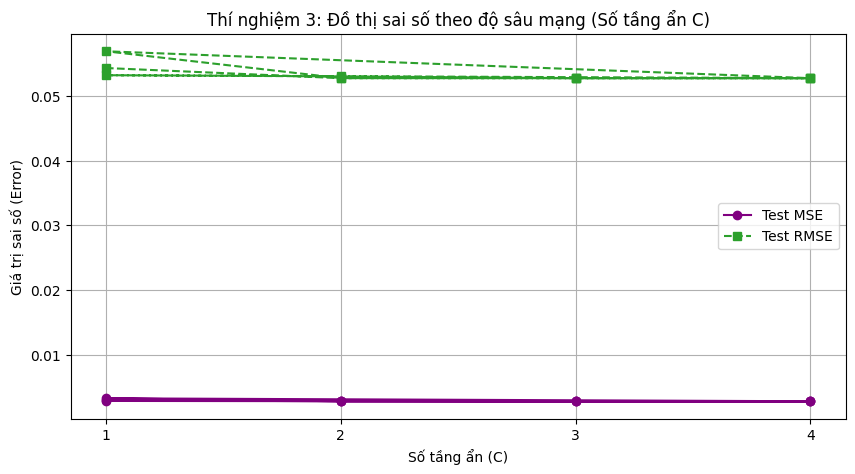

Da luu bang ket qua Experiment 3.


In [ ]:
df_exp3 = pd.DataFrame(exp3_summary)
print(df_exp3.to_string(index=False))

# Vẽ đồ thị biểu diễn sai số theo số tầng ẩn C
plt.figure(figsize=(10, 5))
plt.plot(df_exp3['C (Hidden Layers)'], df_exp3['Test MSE'], marker='o', color='purple', linestyle='-', label='Test MSE')
plt.plot(df_exp3['C (Hidden Layers)'], df_exp3['Test RMSE'], marker='s', color='tab:green', linestyle='--', label='Test RMSE')
plt.title("Thí nghiệm 3: Đồ thị sai số theo độ sâu mạng (Số tầng ẩn C)")
plt.xlabel("Số tầng ẩn (C)")
plt.ylabel("Giá trị sai số (Error)")
plt.xticks(depth_list)
plt.legend()
plt.grid(True)
save_figure("exp3_error_by_hidden_layers.png")
plt.show()
# Luu bang ket qua Experiment 3
df_exp3.to_csv(
    LOG_DIR / "exp3_results.csv",
    index=False,
    encoding="utf-8-sig"
)

log_message("Da luu bang ket qua Experiment 3.")

**Biểu đồ Leaarning Curves**

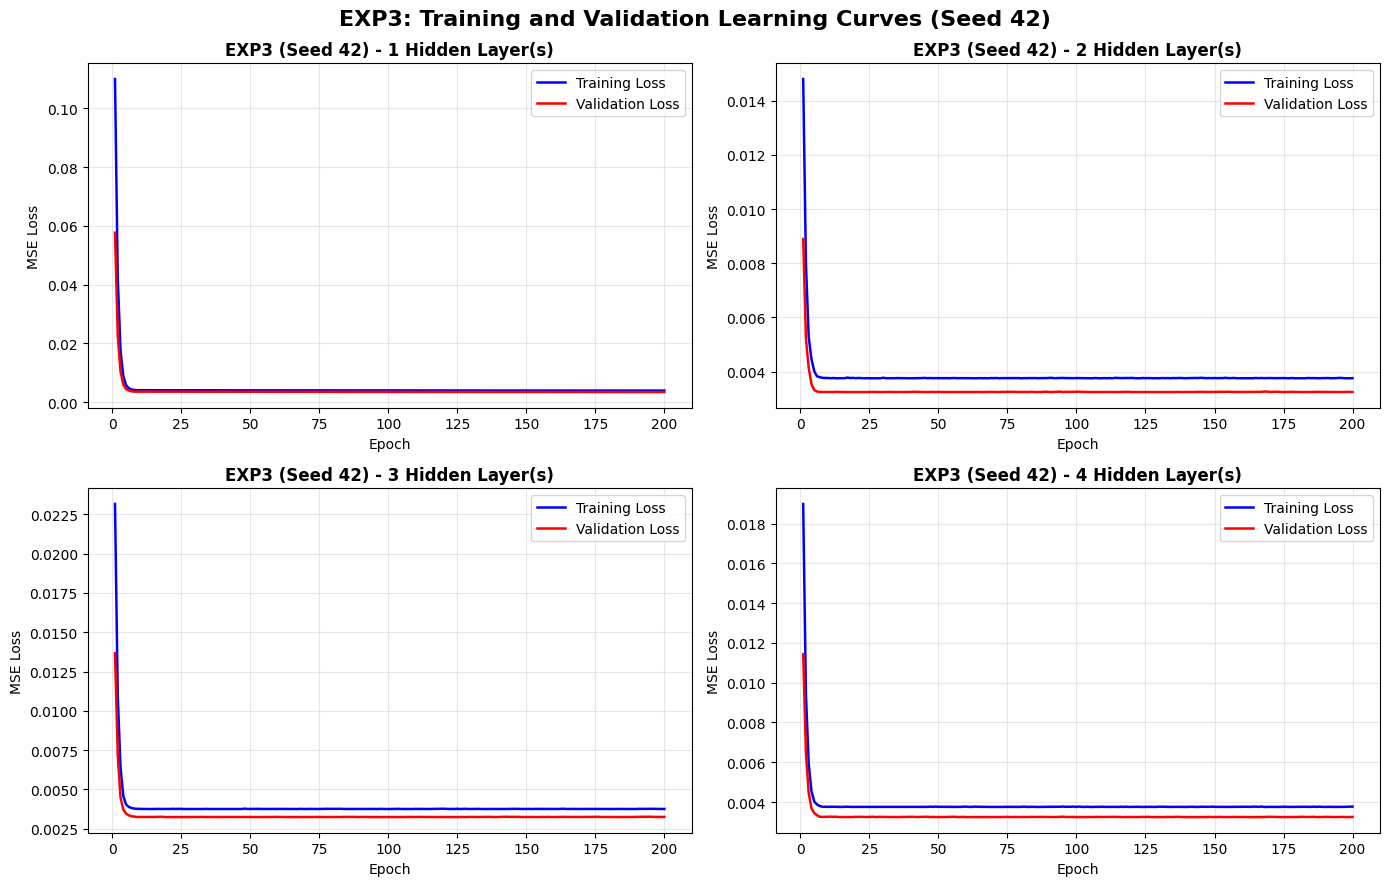

In [ ]:
# Vẽ biểu đồ học tập cho EXP3 (Chỉ lấy seed đầu tiên 42 để tránh vượt quá số lượng 4 subplots)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

# Lọc kết quả chỉ của seed đầu tiên (42) để có đúng 4 cấu hình C từ 1 đến 4
exp3_seed_42 = [res for res in results_exp3 if res["seed"] == 42]

for idx, res in enumerate(exp3_seed_42):
    history = res["history"]
    epochs_range = range(1, len(history["loss"]) + 1)

    axes[idx].plot(
        epochs_range,
        history["loss"],
        label="Training Loss",
        color="blue",
        linewidth=1.8
    )

    axes[idx].plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss",
        color="red",
        linewidth=1.8
    )

    axes[idx].set_title(
        f"EXP3 (Seed 42) - {res['C']} Hidden Layer(s)",
        fontsize=12,
        fontweight="bold"
    )

    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("MSE Loss")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.suptitle(
    "EXP3: Training and Validation Learning Curves (Seed 42)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

#Lưu ảnh
save_figure("exp3_learning_curves.png")

plt.show()


**Nhận xét:**
- Mô hình có 1 tầng ẩn đạt kết quả tốt nhất với $Test MSE$ = $0.005587$ và Test $RMSE$ = 0.074747.
- Khi số tầng ẩn tăng từ 1 lên 4, $Test MSE$ tăng từ $0.005587$ lên $0.006970$, đồng thời $Test RMSE$ cũng tăng.
- Trong phạm vi thí nghiệm này, tăng độ sâu mạng chưa giúp cải thiện kết quả dự đoán mà còn làm tăng thời gian huấn luyện.


In [ ]:
for filename in [
    "exp1_best.pth",
    "exp2_best.pth",
    "exp3_best.pth"
]:
    path = os.path.join("checkpoints", filename)

    if os.path.exists(path):
        print(f"{filename}: {os.path.getsize(path) / 1024:.2f} KB")
    else:
        print(f"Chưa tìm thấy: {filename}")


exp1_best.pth: 2.67 KB
exp2_best.pth: 2.61 KB
exp3_best.pth: 5.60 KB
